# Gas, oil and brine: inverting for fluid contacts (with known ground truth)

This notebook uses an example **shipped with the original Java Delivery
code**: `Tests/InverterTests/Simple3LayerContactsTestProblem`, described in
Appendix 11 of the Delivery paper (`Docs/DeliveryPaper.pdf`). It is harder
than the simple wedge in `synthetic_wedge.ipynb`:

* A 60 m thick reservoir sand dips across 15 traces, getting deeper from left
  to right.
* The fluids are set by **contacts in depth**: gas above 2050 m, oil between
  2050 m and 2120 m, brine below 2120 m. As the sand dips it passes from the
  gas leg, through the oil leg, into brine. On many traces a contact cuts
  through the sand, so one layer holds two fluids.
* The seismic was generated by the Java code from a known model, so we know
  the **ground truth** exactly.

We will:

1. Import the Java example into Python formats.
2. Rebuild the ground truth and check that it reproduces the seismic.
3. **Part A** - invert with the contacts known (as in the original example).
4. **Part B** - pretend we do *not* know where the contacts are, start from
   wrong guesses, and see whether the seismic finds them.
5. **Part C** - repeat Part B with a less certain depth reference, to see why
   depth control matters.

The whole notebook takes about 8 minutes to run.

In [1]:
from pathlib import Path
from xml.etree import ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np

import pydelivery
from pydelivery import Inversion, StateModel, enumerate_fluid_states
from pydelivery.io import import_java_project
from pydelivery.modes import find_modes

java_example = Path("../../au/csiro/JamesGunning/Tests/InverterTests/Simple3LayerContactsTestProblem")
work = Path("contacts_data")
print("pydelivery", pydelivery.__version__)
print("Java example files:", sorted(p.name for p in java_example.iterdir()))

pydelivery 0.2.0
Java example files: ['FFT_wavelet_spectrum.txt', 'ModelDescription.AVO.xml', 'ModelDescription.xml', 'README', 'make_contact_model.pl', 'make_priortrace.sh', 'make_spaghetti_plots.sh', 'near-stack.su', 'near_stack_synth.su', 'prior_traces.su', 'wavelet.su']


## Step 1: import the Java example

The original files are Seismic Unix (`.su`) files and a `ModelDescription.xml`.
One call converts everything to HDF5 and writes a copy of the XML that points
at the new files. The per-trace prior values (`prior_traces.su`) become a small
table of named arrays.

In [2]:
xml_file = import_java_project(java_example / "ModelDescription.xml", work,
                               java_example / "prior_traces.su")
print("new files:", sorted(p.name for p in work.iterdir()))

inv = Inversion.from_files(xml_file, work / "priors.h5")
cfg = inv.cfg
for i, lay in enumerate(cfg.layers):
    rock = f"sand + shale (NG {lay.ng})" if lay.is_permeable else "shale"
    print(f"layer {i + 1}: {lay.name:12s} {rock}")
for c in cfg.contacts:
    print(f"contact {c.label.upper()}: {c.depth} m (uncertainty {c.sigma_depth} m)")
print("reference depth layer:", cfg.master_depth_layer + 1,
      f"(depth {cfg.layers[0].depth} m, +/- {cfg.layers[0].sigma_depth} m)")
print("reservoir isopach (thickness):", cfg.layers[1].thickness, "+/-", cfg.layers[1].sigma_thickness, "m")

new files: ['ModelDescription.xml', 'near-stack.h5', 'priors.h5', 'wavelet.h5']
layer 1: top (1,0)    shale
layer 2: reservoir    sand + shale (NG 0.9)
layer 3: bottom       shale
contact GO: 2050.0 m (uncertainty 0.0 m)
contact OB: 2120.0 m (uncertainty 0.0 m)
reference depth layer: 1 (depth 1900.0 m, +/- 20.0 m)
reservoir isopach (thickness): 60.0 +/- 10.0 m


What the model says:

* **Three layers**: a top shale, the reservoir sand (90 % sand, give or take
  20 %), and a lower shale.
* **One fluid unit with two contacts**: gas over oil (GO) at 2050 m and oil
  over brine (OB) at 2120 m. In this mode fluids are *not* chosen per layer
  with probabilities. They follow from where each layer sits relative to the
  contacts.
* **Depths are hung from the top of layer 1**, picked at 1900 m ± 20 m. The
  inversion converts times to depths using the layer velocities, working down
  from there. That is how it knows which side of a contact each part of the
  sand is on.
* **An isopach**: the sand is 60 m ± 10 m thick (e.g. from wells).

The per-trace prior table holds the picked layer times (in ms) and the
reference depth:

In [3]:
print("columns: top of layer 1, layer 2, layer 3, base of model (ms)")
print(np.round(1000 * inv.priors["time"], 1))

columns: top of layer 1, layer 2, layer 3, base of model (ms)
[[2000. 2050. 2100. 2400.]
 [2000. 2060. 2110. 2400.]
 [2000. 2070. 2120. 2400.]
 [2000. 2080. 2130. 2400.]
 [2000. 2090. 2140. 2400.]
 [2000. 2100. 2150. 2400.]
 [2000. 2110. 2160. 2400.]
 [2000. 2120. 2170. 2400.]
 [2000. 2130. 2180. 2400.]
 [2000. 2140. 2190. 2400.]
 [2000. 2150. 2200. 2400.]
 [2000. 2160. 2210. 2400.]
 [2000. 2170. 2220. 2400.]
 [2000. 2180. 2230. 2400.]
 [2000. 2190. 2240. 2400.]]


## Step 2: the seismic

One near-offset stack, 4 ms sampling. The data were generated without noise,
so everything we see is reflection signal. The inversion still assumes noise
of 0.005 (from the XML), which is a realistic level for amplitudes this size.

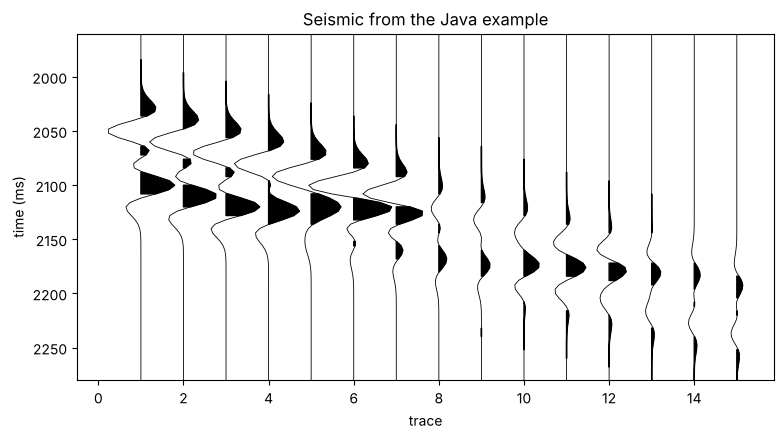

In [4]:
seis = inv.stacks[0]
t = 1000 * (seis.t0[0] + seis.dt * np.arange(seis.n_samples))
x = np.arange(1, inv.n_traces + 1)

def wiggles(data, title, scale=0.06):
    plt.figure(figsize=(9, 4.5))
    for k, tr in enumerate(data):
        s = k + 1 + tr / scale
        plt.plot(s, t, "k", lw=0.6)
        plt.fill_betweenx(t, k + 1, s, where=s > k + 1, color="k")
    plt.gca().invert_yaxis(); plt.ylim(2280, 1960)
    plt.xlabel("trace"); plt.ylabel("time (ms)"); plt.title(title)

wiggles(seis.data, "Seismic from the Java example")
plt.show()

## Step 3: the ground truth

The README of the Java example says the seismic was made from Delivery's
*most likely prior model*: the best model using only the prior and the isopach,
before looking at any seismic. pydelivery can find that same model: it is the
peak of the prior + isopach (we switch the seismic off for this search).

If we have rebuilt the truth correctly, its synthetic seismic must match the
data almost exactly.

In [5]:
truth = []
rng = np.random.default_rng(0)
for i in range(inv.n_traces):
    cfg_i, seis_i = inv.trace_setup(i)
    model = StateModel(cfg_i, enumerate_fluid_states(cfg_i)[0], seis_i)
    peak = find_modes(model, 0, rng, ignore_seismic=True)[0].mean
    p = model.physical(peak[None])
    misfit = model.evaluate(peak[None]).seismic_nll[0]
    truth.append(dict(t=p["t"][0], z=p["z"][0], z_base=p["z_base"][0],
                      S_gas=p["S_eff_gas"][0, 1], S_oil=p["S_eff_oil"][0, 1], misfit=misfit))

z_top = np.array([tr["z"][1] for tr in truth])                 # reservoir top depth
z_bot = np.array([tr["z"][2] for tr in truth])                 # reservoir base depth
print("seismic misfit of the rebuilt truth, per trace (0 = perfect):")
print(np.round([tr["misfit"] for tr in truth], 3))

seismic misfit of the rebuilt truth, per trace (0 = perfect):
[0.164 0.    0.164 0.    0.095 0.    0.155 0.    0.004 0.01  0.017 0.016
 0.005 0.002 0.002]


The misfits are all below 0.2. For scale, a model that was off by one noise
standard deviation at every comparison point would score 8, so these are
essentially perfect matches (the small leftovers come from the Java code's
own approximate search for its peak). So we have the truth. Here it
is in depth: the reservoir sand, coloured by fluid, with the two contacts.

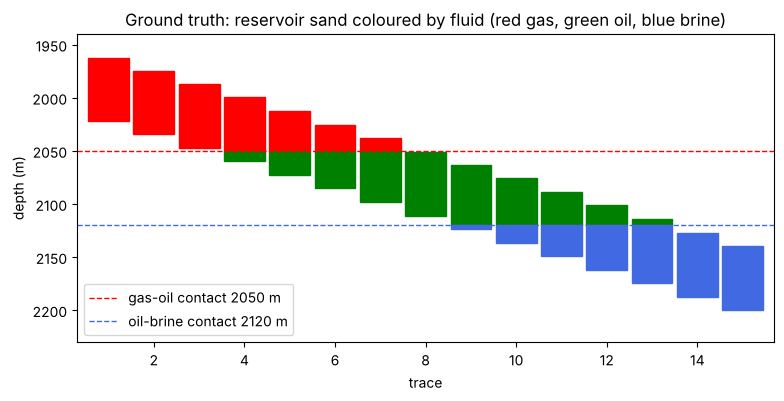

In [6]:
GO, OB = 2050.0, 2120.0
fig, ax = plt.subplots(figsize=(9, 4))
for k in range(len(x)):
    top, bot = z_top[k], z_bot[k]
    for lo, hi, colour in ((top, min(bot, GO), "red"), (max(top, GO), min(bot, OB), "green"),
                           (max(top, OB), bot, "royalblue")):
        if hi > lo:
            ax.add_patch(plt.Rectangle((x[k] - 0.45, lo), 0.9, hi - lo, color=colour))
ax.axhline(GO, color="red", ls="--", lw=1, label="gas-oil contact 2050 m")
ax.axhline(OB, color="royalblue", ls="--", lw=1, label="oil-brine contact 2120 m")
ax.set_xlim(0.3, 15.7); ax.set_ylim(2230, 1940)
ax.set_xlabel("trace"); ax.set_ylabel("depth (m)")
ax.set_title("Ground truth: reservoir sand coloured by fluid (red gas, green oil, blue brine)")
ax.legend(loc="lower left"); plt.show()

S_gas_true = np.array([tr["S_gas"] for tr in truth])
S_oil_true = np.array([tr["S_oil"] for tr in truth])

On traces 1-3 the sand is all gas. On traces 4-7 the gas-oil contact cuts
through it, on 8-13 the oil-brine contact does, and on 14-15 it is all brine.

A useful single number for "how much hydrocarbon is in the sand" is the
**effective saturation**: the saturation averaged over the whole layer
thickness. A sand half in gas (80 % gas saturation) and half in brine has an
effective gas saturation of 0.4.

## Part A: invert with the contacts known

This is the original example. For each trace the inversion samples the layer
times, rock properties and reference depth; the contacts are fixed. Where a
contact falls inside the sand, the sand is split into two sub-layers, each
with its own fluid, and the contact itself makes a reflection.

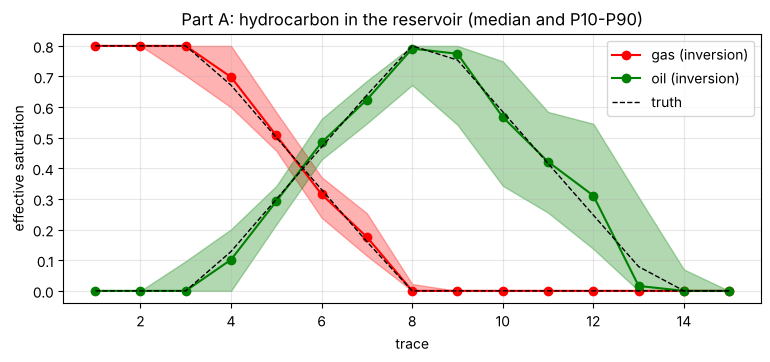

In [7]:
results_A = inv.run(n_samples=600, seed=1)
inv.save(work / "results_A.h5", results_A)

def band(ax, values, colour, label):
    p10, p50, p90 = np.percentile(values, [10, 50, 90], axis=1)
    ax.fill_between(x, p10, p90, color=colour, alpha=0.3)
    ax.plot(x, p50, "o-", color=colour, label=label)

fig, ax = plt.subplots(figsize=(9, 3.5))
band(ax, np.array([r.samples["S_gas"][:, 1] for r in results_A]), "red", "gas (inversion)")
band(ax, np.array([r.samples["S_oil"][:, 1] for r in results_A]), "green", "oil (inversion)")
ax.plot(x, S_gas_true, "k--", lw=1, label="truth")
ax.plot(x, S_oil_true, "k--", lw=1)
ax.set_xlabel("trace"); ax.set_ylabel("effective saturation")
ax.set_title("Part A: hydrocarbon in the reservoir (median and P10-P90)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

The inversion tracks the gas and oil in the sand trace by trace, including the
traces where a contact splits the layer.

The Delivery paper points out a neat side effect of contacts: when a contact
shows up in the seismic, it is an event at a *known depth*, so it pins down
the depth of the whole layer stack. Here is the depth uncertainty of the
reservoir top. The prior uncertainty (from the ±20 m reference depth and the
velocities) is shown for comparison.

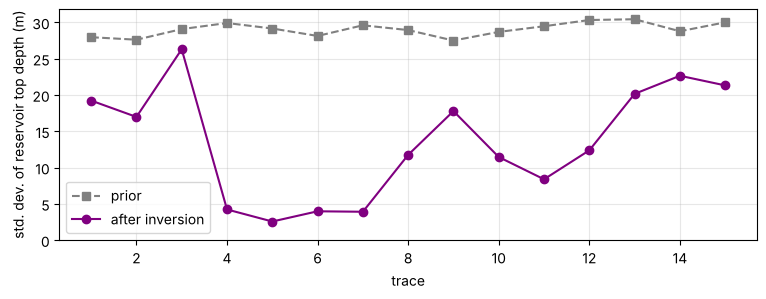

In [8]:
sd_post = np.array([r.samples["z"][:, 1].std() for r in results_A])
prior_runs = inv.run(n_samples=600, seed=2, ignore_seismic=True)
sd_prior = np.array([r.samples["z"][:, 1].std() for r in prior_runs])

plt.figure(figsize=(9, 3))
plt.plot(x, sd_prior, "s--", color="gray", label="prior")
plt.plot(x, sd_post, "o-", color="purple", label="after inversion")
plt.xlabel("trace"); plt.ylabel("std. dev. of reservoir top depth (m)")
plt.ylim(0, None); plt.legend(); plt.grid(alpha=0.3); plt.show()

Before the seismic, the reservoir top depth is uncertain by about ±29 m
(the ±20 m reference depth plus uncertain velocities). After inversion:

* **Traces 4-7**: about ±3-5 m. The bright gas-oil contact reflection sits
  inside the sand at a known depth (2050 m), which pins the whole layer.
* **Traces 9-12**: about ±8-12 m. The oil-brine contact helps too, but its
  reflection is weaker.
* **Traces 1-3 and 13-15**: no contact inside the sand, so only the seismic
  times and velocities help; the depth stays more uncertain.

This is the effect shown in Figure 21 of the Delivery paper.

## Part B: where are the contacts?

Now a harder question. Suppose we only have rough ideas about the contacts:

* gas-oil contact at **2030 m ± 25 m** (truth: 2050 m)
* oil-brine contact at **2145 m ± 25 m** (truth: 2120 m)

Both guesses are wrong by 20-25 m. We also assume a well nearby gives the
reference depth to ±2 m (instead of ±20 m). We change these values in the XML
and invert again. The seismic data are unchanged.

Each trace is inverted on its own, so every trace gives its own estimate of
each contact.

In [9]:
def edit_xml(source, target, go_depth, ob_depth, contact_sigma, ref_sigma):
    tree = ET.parse(source)
    root = tree.getroot()
    contacts = root.findall(".//fluid_units_and_contacts//contact")
    for c, depth in zip(contacts, (go_depth, ob_depth)):
        c.find("depth").text = str(depth)
        c.find("sigma_depth").text = str(contact_sigma)
    root.find(".//top_layer/sigma_depth").text = str(ref_sigma)
    tree.write(target)
    return target

xml_B = edit_xml(xml_file, work / "unknown_contacts_tight_depth.xml", 2030, 2145, 25, 2)
inv_B = Inversion.from_files(xml_B, work / "priors.h5")
print(inv_B.cfg.contacts, "reference depth +/-", inv_B.cfg.layers[0].sigma_depth, "m")
results_B = inv_B.run(n_samples=500, seed=1)
inv_B.save(work / "results_B.h5", results_B)

[Contact(upper=3, lower=1, depth=2030.0, sigma_depth=25.0), Contact(upper=1, lower=0, depth=2145.0, sigma_depth=25.0)] reference depth +/- 2.0 m


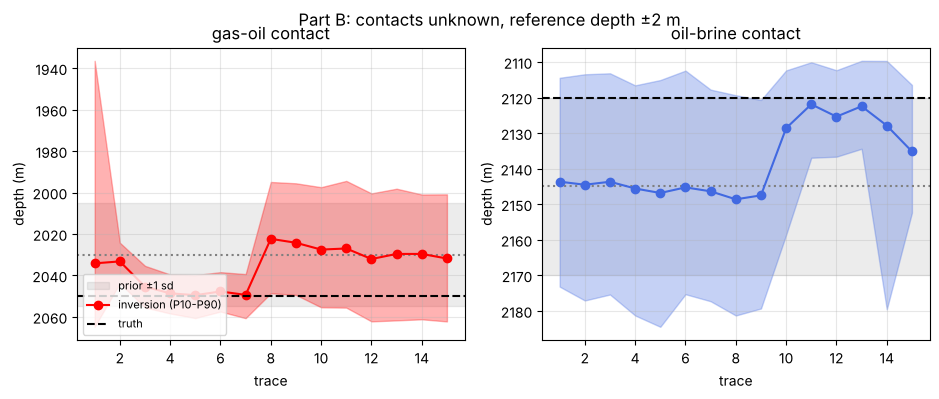

In [10]:
def contact_plot(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
    for ax, k, name, true, prior, colour in ((axes[0], 0, "gas-oil", GO, 2030, "red"),
                                             (axes[1], 1, "oil-brine", OB, 2145, "royalblue")):
        c = np.array([r.samples["contact_depth"][:, k] for r in results])
        ax.axhspan(prior - 25, prior + 25, color="gray", alpha=0.15, label="prior ±1 sd")
        ax.axhline(prior, color="gray", ls=":")
        band(ax, c, colour, "inversion (P10-P90)")
        ax.axhline(true, color="k", ls="--", label="truth")
        ax.invert_yaxis(); ax.set_xlabel("trace"); ax.set_ylabel("depth (m)")
        ax.set_title(f"{name} contact"); ax.grid(alpha=0.3)
    axes[0].legend(loc="lower left", fontsize=8)
    fig.suptitle(title); plt.show()

contact_plot(results_B, "Part B: contacts unknown, reference depth ±2 m")

Where a contact cuts through the sand, the seismic sees it: a reflection
inside the reservoir. On those traces the estimate moves from the wrong guess
to the truth.

* **Gas-oil contact:** on traces 3-7 it homes in on 2050 m, to within about
  ±5 m. Gas against oil is a strong contrast, so this reflection is bright.
* **Oil-brine contact:** on traces 10-13 it moves from the 2145 m guess to
  about 2120-2128 m, but the range stays wider (±10-15 m) because oil against
  brine is a much weaker contrast.

Where a contact is *not* inside the sand, the seismic only says "not here":
the contact must lie above or below the sand. The estimate then stays close
to the prior. That is the right behaviour: the inversion only claims what the
data support.

The fluids in the sand are still recovered well, even though the contacts were
wrong to start with:

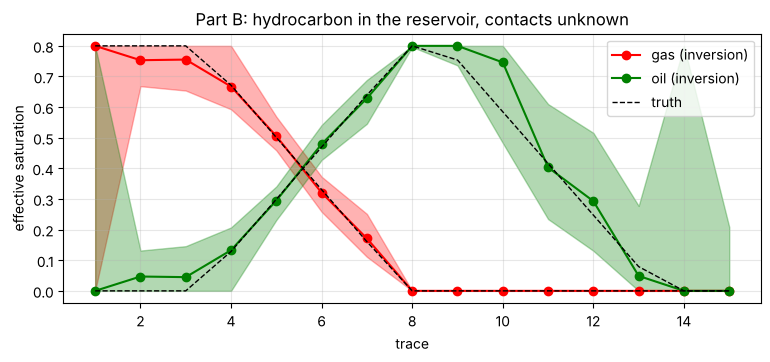

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
band(ax, np.array([r.samples["S_gas"][:, 1] for r in results_B]), "red", "gas (inversion)")
band(ax, np.array([r.samples["S_oil"][:, 1] for r in results_B]), "green", "oil (inversion)")
ax.plot(x, S_gas_true, "k--", lw=1, label="truth"); ax.plot(x, S_oil_true, "k--", lw=1)
ax.set_xlabel("trace"); ax.set_ylabel("effective saturation")
ax.set_title("Part B: hydrocarbon in the reservoir, contacts unknown")
ax.legend(); ax.grid(alpha=0.3); plt.show()

Compared with Part A the bands are wider at the edges. On trace 1 the
gas-oil contact is so uncertain that it could sit inside the sand, and on
trace 14 the oil-brine contact could sit deep enough to leave oil in it. The
inversion keeps those possibilities open because the seismic there cannot
rule them out.

## Part C: why the depth reference matters

The seismic measures **time**, not depth. A contact seen inside the sand
tells us its *time*; turning that into a depth needs the depth of the
reference layer plus the velocities. Go back to the original reference depth,
±20 m, and repeat Part B:

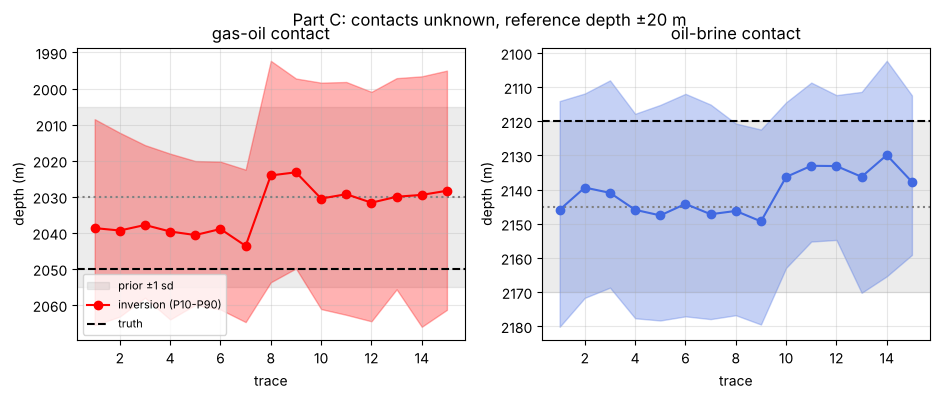

In [12]:
xml_C = edit_xml(xml_file, work / "unknown_contacts_loose_depth.xml", 2030, 2145, 25, 20)
inv_C = Inversion.from_files(xml_C, work / "priors.h5")
results_C = inv_C.run(n_samples=500, seed=1)
inv_C.save(work / "results_C.h5", results_C)
contact_plot(results_C, "Part C: contacts unknown, reference depth ±20 m")

The contacts still move towards the truth on the traces that see them, but
less far, and their ranges stay nearly as wide as the prior. The inversion knows *when*
the contact is, but with ±20 m of slack in the depth reference it cannot say
precisely *where*. Combining seismic with good depth control (wells) is what
nails the contacts.

## Summary

* We imported an example from the original Java Delivery distribution, rebuilt
  its ground truth, and confirmed that the truth reproduces the seismic.
* **Part A**: with contacts known, the inversion recovers the gas and oil
  saturation trace by trace, including layers split by a contact.
* **Part B**: starting from contact guesses 20-25 m wrong, the inversion found
  the true contact depths wherever a contact cuts the reservoir (gas-oil to
  about ±5 m, the fainter oil-brine to about ±10-15 m), and left the others
  near the prior.
* **Part C**: the precision of those contacts is limited by the depth
  reference, because seismic measures time.

Results are in `contacts_data/results_A.h5`, `results_B.h5` and
`results_C.h5`; load them with `pydelivery.read_results(...)`.